In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

In [5]:
df=pd.read_csv("AIML Dataset.csv")

In [6]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110813 entries, 0 to 110812
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            110813 non-null  int64  
 1   type            110813 non-null  object 
 2   amount          110813 non-null  float64
 3   nameOrig        110813 non-null  object 
 4   oldbalanceOrg   110813 non-null  float64
 5   newbalanceOrig  110813 non-null  float64
 6   nameDest        110813 non-null  object 
 7   oldbalanceDest  110813 non-null  float64
 8   newbalanceDest  110812 non-null  float64
 9   isFraud         110812 non-null  float64
 10  isFlaggedFraud  110812 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 9.3+ MB


In [8]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [9]:
df["isFraud"].value_counts()

,count
isFraud,
0.0,110692
1.0,120


In [10]:
df["isFlaggedFraud"].value_counts()

,count
isFlaggedFraud,
0.0,110812


In [11]:
df.isnull().sum().sum()

np.int64(3)

In [12]:
df.shape[0]

110813

In [13]:
round((df["isFraud"].value_counts()[1] / df.shape[0]) *100,2)

np.float64(0.11)

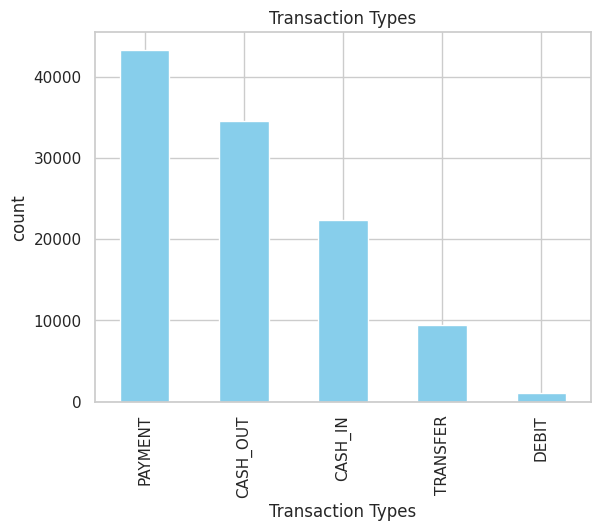

In [14]:
df["type"].value_counts().plot(kind='bar',title='Transaction Types',color='skyblue')
plt.xlabel('Transaction Types')
plt.ylabel('count')
plt.show()

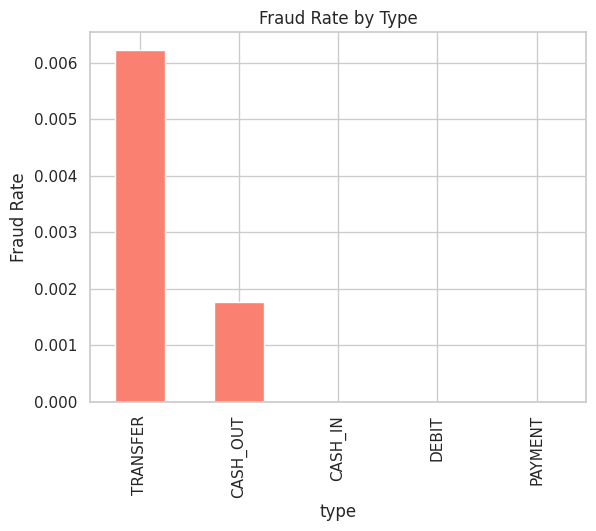

In [15]:
fraud_by_type=df.groupby('type')['isFraud'].mean().sort_values(ascending=False)
fraud_by_type.plot(kind='bar',title='Fraud Rate by Type',color='salmon')
plt.ylabel('Fraud Rate')
plt.show()

In [17]:
fraud_by_type

,isFraud
type,
TRANSFER,0.006229
CASH_OUT,0.001765
CASH_IN,0.000000
DEBIT,0.000000
PAYMENT,0.000000


In [16]:
df['amount'].describe().astype(int)

,amount
count,110813
mean,175905
std,347036
min,0
25%,10234
50%,55244
75%,214508
max,10000000


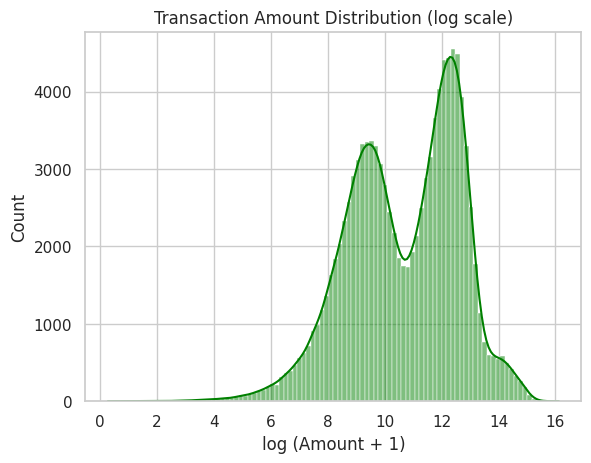

In [18]:
sns.histplot(np.log1p(df['amount']) , bins=100 , kde=True , color="green")
plt.title("Transaction Amount Distribution (log scale)")
plt.xlabel("log (Amount + 1)")
plt.show()

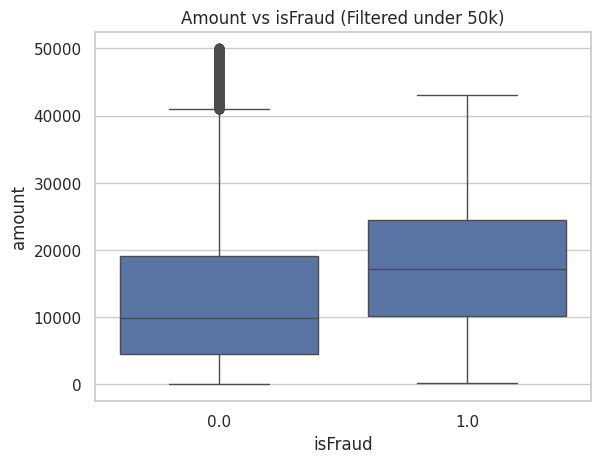

In [19]:
sns.boxplot(data=df[df['amount'] < 50000 ],x='isFraud' ,y='amount')
plt.title("Amount vs isFraud (Filtered under 50k)")
plt.show()

In [20]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [21]:
df['balanceDiffOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['balanceDiffDest'] = df['oldbalanceDest'] - df['newbalanceDest']

In [22]:
(df['balanceDiffOrig'] < 0).sum()

np.int64(22360)

In [23]:
(df['balanceDiffDest'] < 0).sum()

np.int64(45249)

In [24]:
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0,1864.28,0.0


In [ ]:
fraud_per_step = df[df['isFraud'] == 1]['step'].value_counts().sort_index()
plt.plot(fraud_per_step.index , fraud_per_step.values , label='Frauds per Step')
plt.xlabel('Step (Time)')
plt.ylabel('Number of Frauds')
plt.title('Frauds Over Time')
plt.grid(True)
plt.show()

In [25]:
df.drop(columns='step', inplace=True)

In [26]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0,181.00,21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0,11668.14,0.0


In [27]:
top_senders = df['nameOrig'].value_counts().head(10)

In [28]:
top_senders

,count
nameOrig,
C1231006815,1
C1666544295,1
C1305486145,1
C840083671,1
C2048537720,1
C90045638,1
C154988899,1
C1912850431,1
C1265012928,1


In [29]:
top_recievers = df['nameDest'].value_counts().head(10)

In [30]:
top_recievers

,count
nameDest,
C985934102,78
C1286084959,75
C248609774,72
C1590550415,71
C2083562754,68
C977993101,67
C665576141,66
C1360767589,63
C451111351,60


In [31]:
fraud_users = df[df['isFraud'] == 1]['nameOrig'].value_counts().head(10)

In [32]:
fraud_users

,count
nameOrig,
C1305486145,1
C840083671,1
C1420196421,1
C2101527076,1
C137533655,1
C1118430673,1
C749981943,1
C1334405552,1
C467632528,1


In [33]:
fraud_types = df[df['type'].isin(['TRANSFER' , 'CASH_OUT'])]

In [34]:
fraud_types['type'].value_counts()

,count
type,
CASH_OUT,34554
TRANSFER,9472


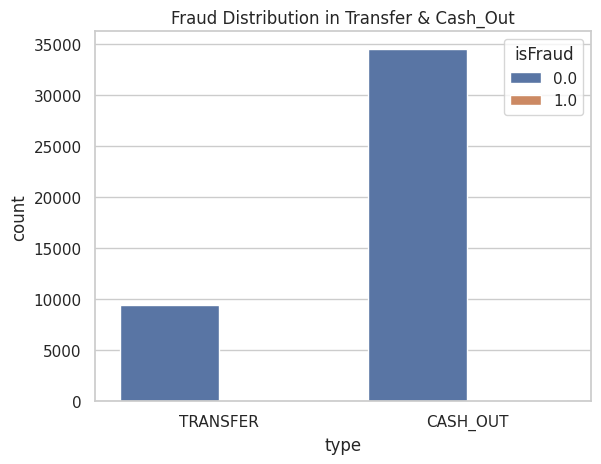

In [35]:
sns.countplot(data=fraud_types , x='type' , hue='isFraud')
plt.title("Fraud Distribution in Transfer & Cash_Out")
plt.show()

In [36]:
corr = df[['amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest','isFraud']].corr()

In [38]:
corr

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.000000,-0.012842,-0.018990,0.241862,0.370074,0.037206
oldbalanceOrg,-0.012842,1.000000,0.998911,0.100822,0.070228,-0.003736
newbalanceOrig,-0.018990,0.998911,1.000000,0.102394,0.069191,-0.010312
oldbalanceDest,0.241862,0.100822,0.102394,1.000000,0.940235,-0.009178
newbalanceDest,0.370074,0.070228,0.069191,0.940235,1.000000,-0.006218
isFraud,0.037206,-0.003736,-0.010312,-0.009178,-0.006218,1.000000


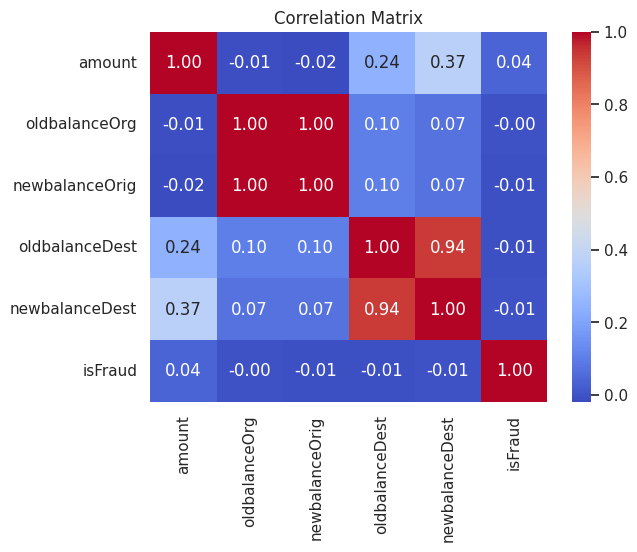

In [37]:
sns.heatmap(corr,annot=True,cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

In [39]:
zero_after_transfer=df[
    (df['oldbalanceOrg'] > 0) &
    (df['newbalanceOrig'] == 0) &
    (df["type"].isin(['TRANSFER','CASH_OUT']))
]

In [40]:
len(zero_after_transfer)

17073

In [41]:
zero_after_transfer.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
2,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1.0,0.0,181.0,0.00
3,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1.0,0.0,181.0,21182.00
15,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0.0,0.0,15325.0,-46430.44
19,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0.0,0.0,705.0,22425.00
24,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0.0,0.0,10835.0,-2712905.89


In [42]:
df['isFraud'].value_counts()

,count
isFraud,
0.0,110692
1.0,120


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [44]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0,181.00,21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0,11668.14,0.0


In [45]:
df_model=df.drop(['nameOrig','nameDest','isFlaggedFraud'], axis=1)

In [46]:
df_model.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0.0,9839.64,0.0
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0.0,1864.28,0.0
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,1.0,181.00,0.0
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1.0,181.00,21182.0
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0.0,11668.14,0.0


In [47]:
categorical=['type']
numeric= ['amount','oldbalanceOrg','newbalanceOrig','oldbalanceDest','newbalanceDest']

In [48]:
y=df_model['isFraud']
X=df_model.drop('isFraud',axis=1)

In [49]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3)

In [50]:
preprocessor=ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),numeric),
        ('cat',OneHotEncoder(drop='first'),categorical)
    ],
    remainder="drop"
)

In [51]:
pipeline=Pipeline([
    ('preprocessor',preprocessor),
    ('classifier',LogisticRegression(class_weight='balanced',max_iter=1000))
])

In [52]:
X_train = X_train.dropna()
y_train = y_train.loc[X_train.index]

In [53]:
print(y_train.isnull().sum())

0


In [54]:
print(np.isnan(y_train).sum())

0


In [55]:
print(y_train[y_train.isnull()])

Series([], Name: isFraud, dtype: float64)


In [56]:
print(df[df['isFraud'].isnull()])

            type     amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
110812  CASH_OUT  118777.61  C1510313227            0.0             0.0   

          nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  \
110812  C601893033       1019293.0             NaN      NaN             NaN   

        balanceDiffOrig  balanceDiffDest  
110812              0.0              NaN  


In [57]:
df = df.dropna(subset=['isFraud'])

In [58]:
X = df.drop('isFraud', axis=1)
y = df['isFraud']

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [60]:
pipeline.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [61]:
y_predict = pipeline.predict(X_test)

In [62]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

         0.0       1.00      0.83      0.91     22145
         1.0       0.00      1.00      0.01        18

    accuracy                           0.83     22163
   macro avg       0.50      0.92      0.46     22163
weighted avg       1.00      0.83      0.91     22163



In [63]:
confusion_matrix(y_test,y_predict)

array([[18416,  3729],
       [    0,    18]])

In [64]:
pipeline.score(X_test,y_test)*100

83.17466047015296

In [67]:
import pandas as pd

df = pd.read_csv("/content/AIML Dataset.csv")

print(df.shape)
df.head()

(5057857, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0.0


In [68]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model = joblib.load("fraud_model.pkl")

st.title("💳 Fraud Detection System")

st.write("Enter transaction details.")

step = st.number_input("Step", 0)

type = st.selectbox(
    "Transaction Type",
    ["PAYMENT", "TRANSFER", "CASH_OUT", "DEBIT", "CASH_IN"]
)

amount = st.number_input("Amount")

oldbalanceOrg = st.number_input("Old Balance Origin")

newbalanceOrig = st.number_input("New Balance Origin")

oldbalanceDest = st.number_input("Old Balance Destination")

newbalanceDest = st.number_input("New Balance Destination")

type_map = {
    "PAYMENT":0,
    "TRANSFER":1,
    "CASH_OUT":2,
    "DEBIT":3,
    "CASH_IN":4
}

type = type_map[type]

if st.button("Predict"):

    data = pd.DataFrame([[

        step,
        type,
        amount,
        0,
        oldbalanceOrg,
        newbalanceOrig,
        0,
        oldbalanceDest,
        newbalanceDest

    ]], columns=[
        "step",
        "type",
        "amount",
        "nameOrig",
        "oldbalanceOrg",
        "newbalanceOrig",
        "nameDest",
        "oldbalanceDest",
        "newbalanceDest"
    ])

    prediction = model.predict(data)

    if prediction[0] == 1:
        st.error("🚨 Fraudulent Transaction")
    else:
        st.success("✅ Legitimate Transaction")

Writing app.py


In [69]:
!streamlit run app.py &>/content/logs.txt &

In [72]:
!pip install pyngrok

In [73]:
!streamlit run app.py &>/content/logs.txt &

In [76]:
from pyngrok import ngrok

ngrok.set_auth_token("3GdjiWEdNhgitbiOMPwQ0FxWzbA_6bzte4WzujsfEg1n9wX7s")

In [78]:
ngrok.kill()

In [79]:
!streamlit run app.py &>/content/logs.txt &

In [80]:
import time
time.sleep(3)

In [81]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("🌐 Public URL:", public_url)

🌐 Public URL: NgrokTunnel: "https://oxygen-daughter-possibly.ngrok-free.dev" -> "http://localhost:8501"


In [82]:
!cat /content/logs.txt

/bin/bash: line 1: streamlit: command not found


In [83]:
!curl http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [84]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(
    addr=8501,
    proto="http"
)

print("OPEN THIS:", public_url)

OPEN THIS: NgrokTunnel: "https://oxygen-daughter-possibly.ngrok-free.dev" -> "http://localhost:8501"


In [85]:
!streamlit run /content/app.py --server.address 0.0.0.0 --server.port 8501 > /content/logs.txt 2>&1 &

In [86]:
import time
time.sleep(5)

In [87]:
!curl http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [88]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501)

print("🌐 APP LINK:", public_url)

🌐 APP LINK: NgrokTunnel: "https://oxygen-daughter-possibly.ngrok-free.dev" -> "http://localhost:8501"


In [89]:
!cat /content/logs.txt

/bin/bash: line 1: streamlit: command not found


In [90]:
!curl http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server


In [91]:
!pip install -q streamlit

In [92]:
!streamlit run /content/app.py --server.address 0.0.0.0 --server.port 8501 > /content/logs.txt 2>&1 &

In [93]:
import time
time.sleep(5)

In [94]:
!curl http://127.0.0.1:8501

<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
 See the License for the specific language governing permissions and
 limitations under the License.
-->

<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta
      name="viewport"
      content="width=device-width, initial-scale=1, shrink-to-fit=no"
    />
    <link rel="shortcut icon" href="./favicon.png" />
    <link
      rel="preload"
      href="./static/media/SourceSansVF-Upright.ttf.BsWL4Kly.woff2"
      as="font"
      type="font/woff2"
      crossorig

In [96]:
from pyngrok import ngrok

ngrok.kill()

In [97]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Mon, 16 Nov 2026 15:53:22 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Mon, 16 Nov 2026 15:50:18 GMT
etag: "f6e5da575c7532bd0a5350bc47e22d2d"
cache-control: no-cache



In [98]:
from pyngrok import ngrok

tunnel = ngrok.connect(
    addr="http://127.0.0.1:8501",
    proto="http"
)

print("🌐 APP LINK:", tunnel.public_url)

🌐 APP LINK: https://oxygen-daughter-possibly.ngrok-free.dev


In [99]:
!Is -1 /content/

/bin/bash: line 1: Is: command not found


In [100]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith('.pkl'):
            print(os.path.join(root, file))

In [102]:
import joblib
joblib.dump(pipeline,'/content/fraud_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [103]:
import os
print(os.path.exists('/content/fraud_model.pkl'))

True


In [105]:
%cd /content
!streamlit run app.py --server.port 8501 &

/content


2026-11-16 16:10:51.129 Port 8501 is not available


In [106]:
from pyngrok import ngrok
tunnel=ngrok.connect(8501)
print("https://oxygen-daughter-possibly.ngrok-free.dev",
tunnel.public_url)

https://oxygen-daughter-possibly.ngrok-free.dev https://oxygen-daughter-possibly.ngrok-free.dev


In [107]:
!streamlit run /content/app.py --server.port 8501 > /content/ streamlit.log 2>&1 &

/bin/bash: line 1: /content/: Is a directory


In [108]:
!cat /content/streamlit.log

cat: /content/streamlit.log: No such file or directory


In [109]:
!streamlit run /content/app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [110]:
!cat /content/streamlit.log



2026-11-16 16:17:02.550 Port 8501 is not available


In [111]:
!tail -30 /content/streamlit.log



2026-11-16 16:17:02.550 Port 8501 is not available


In [112]:
!curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Mon, 16 Nov 2026 16:19:37 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Mon, 16 Nov 2026 15:50:18 GMT
etag: "f6e5da575c7532bd0a5350bc47e22d2d"
cache-control: no-cache



In [113]:
from pyngrok import ngrok
ngrok.kill()
tunnel=ngrok.connect(8501)
print("https://oxygen-daughter-possibly.ngrok-free.dev",
tunnel.public_url)

https://oxygen-daughter-possibly.ngrok-free.dev https://oxygen-daughter-possibly.ngrok-free.dev


In [115]:
pipeline.fit(X_train, y_train)
import joblib
joblib.dump(pipeline,'/content/fraud_model.pkl')

['/content/fraud_model.pkl']

In [116]:
from pyngrok import ngrok
ngrok.kill()
tunnel=ngrok.connect(8501)
print("https://oxygen-daughter-possibly.ngrok-free.dev",
tunnel.public_url)

https://oxygen-daughter-possibly.ngrok-free.dev https://oxygen-daughter-possibly.ngrok-free.dev


In [119]:
from pyngrok import ngrok
ngrok.kill()
tunnel=ngrok.connect(8501)
print("https://oxygen-daughter-possibly.ngrok-free.dev",
tunnel.public_url)

https://oxygen-daughter-possibly.ngrok-free.dev https://oxygen-daughter-possibly.ngrok-free.dev
